# Notebook 4 — Validación semisintética (OE6 · bloque R6)

**Pregunta:** *¿funciona el método cuando conocemos la respuesta?*

Se conservan las **covariables reales** (N = 3 028 avisos, sus ubicaciones, edificios y bloques) y se simulan el tratamiento y el
resultado con un efecto **conocido** θ₀ = 0,05 (≈ 5,1 % por baño). Las funciones m₀(X) = E[T|X] y g₀(X) se ajustan una vez sobre los datos
reales, de modo que la confusión observada tiene la forma no lineal del mercado limeño. Luego se plantan, por escenario:

| Escenario | Qué se planta | Qué debería pasar |
|---|---|---|
| E1 | Nada (solo confusión observada) | DML insesgado y cobertura ≈ 95 %; el control inadmisible (precio/m²) sesga |
| E2–E4 | Confusor omitido U con R² parcial ≈ 0,02 / 0,07 / 0,15 con T y con Y | DML sesgado hacia arriba, creciente con la fuerza de U; la cota de sensibilidad debe contener θ₀ |
| E5 | θ heterogéneo: 0,03 (clase1), 0,05 (clase2), 0,08 (clase3) | GATE recupera cada θ_g; la prueba de Wald detecta diferencias |
| E6 | Shocks comunes por bloque de 1 km en T y en Y | EE iid subcubren; EE agrupados deben corregirlo |

100 réplicas por escenario. Estimadores: OLS sin ajustar, hedónico OLS con el conjunto S1, y DML-PLR (el mismo del notebook 3, con una
sola partición por réplica). Métricas: sesgo medio, RMSE, cobertura del IC 95 % y longitud media del IC.

> La simulación **no** demuestra que el efecto estimado en Lima sea causal; muestra si el software recupera el parámetro cuando el mundo
> generador es conocido y en qué escenarios falla.

In [1]:
import os, json, warnings; warnings.filterwarnings("ignore")
os.environ["OMP_NUM_THREADS"] = "2"; os.environ["PYTHONPATH"] = os.getcwd()
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from joblib import Parallel, delayed
from sklearn.model_selection import cross_val_predict
from causal_utils import *
import semisintetico as ss

sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110
ORIGEN = "notebook4_semisintetico.ipynb"
base = pd.read_csv("../csv/data_causal_base.csv")
d = muestra(base); X = matriz(d); Xv = X.values
Y, T = d["Y"].values, d["T"].values
theta_hat = json.loads((RES / "resumen_principal.json").read_text(encoding="utf-8"))["theta"]

# Componentes del DGP ajustados sobre los datos reales
mod = LEARNERS["HGB"]
m0 = mod(SEED).fit(Xv, T).predict(Xv)
g0 = mod(SEED).fit(Xv, Y - theta_hat * T).predict(Xv)
sd_v = np.std(T - cross_val_predict(mod(SEED), Xv, T, cv=5))
sd_e = np.std(Y - theta_hat * T - cross_val_predict(mod(SEED), Xv, Y - theta_hat * T, cv=5))
ins = dict(m0=m0, g0=g0, sd_v=sd_v, sd_e=sd_e, clase=d["distrito_clase"].values,
           celda_codes=pd.factorize(d["celda_1km"])[0])
edif, celda, area = d["edificio_id"].values, d["celda_1km"].values, d["area"].values
verdad = {e: ss.theta_plr_verdadero(ins, e) for e in ss.ESCENARIOS}
print(f"N = {len(d)} | sd(v) = {sd_v:.3f} | sd(e) = {sd_e:.3f} | theta verdadero por escenario:", {k[:2]: round(v, 4) for k, v in verdad.items()})

N = 3028 | sd(v) = 0.489 | sd(e) = 0.337 | theta verdadero por escenario: {'E1': 0.05, 'E2': 0.05, 'E3': 0.05, 'E4': 0.05, 'E5': 0.0503, 'E6': 0.05}


In [2]:
import time
R = 100
t0 = time.time()
salida = Parallel(n_jobs=8, verbose=0)(delayed(ss.replica)(ins, e, r, Xv, area, edif, celda)
                                      for e in ss.ESCENARIOS for r in range(R))
print(f"{len(salida)} réplicas en {time.time() - t0:.0f} s")
est = pd.DataFrame([o for out, _ in salida for o in out])
aux = [a for _, a in salida]
est["verdad"] = est["escenario"].map(verdad)
est.to_csv(RES / "sim_replicas.csv", index=False)

600 réplicas en 409 s


In [3]:
def cubre(t, s, v):
    return np.where(np.isnan(s), np.nan, (t - 1.96 * s <= v) & (v <= t + 1.96 * s))

est["cob_edif"] = cubre(est.theta, est.se_edif, est.verdad)
est["cob_iid"] = cubre(est.theta, est.se_iid, est.verdad)
est["cob_celda"] = cubre(est.theta, est.se_celda, est.verdad)
est["long_ic"] = 2 * 1.96 * est.se_edif
orden_est = ["OLS sin ajustar", "Hedónico OLS (S1)", "DML PLR (S1)", "DML + precio/m² (inadmisible)"]
r6 = (est.groupby(["escenario", "estimador"], sort=False)
         .apply(lambda g: pd.Series({"verdad": g.verdad.iloc[0], "media theta": g.theta.mean(),
                                     "sesgo": (g.theta - g.verdad).mean(),
                                     "RMSE": np.sqrt(((g.theta - g.verdad) ** 2).mean()),
                                     "cobertura EE edificio": 100 * g.cob_edif.mean(),
                                     "cobertura EE iid": 100 * g.cob_iid.mean() if g.cob_iid.notna().any() else np.nan,
                                     "cobertura EE celda": 100 * g.cob_celda.mean() if g.cob_celda.notna().any() else np.nan,
                                     "long. media IC": g.long_ic.mean()}))
         .reset_index())
r6["estimador"] = pd.Categorical(r6["estimador"], orden_est)
r6 = r6.sort_values(["escenario", "estimador"]).reset_index(drop=True)
r6["estimador"] = r6["estimador"].astype(str)
guardar_tabla(r6, "R6_simulacion", origen=ORIGEN, decimales=3)
r6.round(3)

,escenario,estimador,verdad,media theta,sesgo,RMSE,cobertura EE edificio,cobertura EE iid,cobertura EE celda,long. media IC
0,E1 Sin U (efecto homogéneo),OLS sin ajustar,0.05,0.337,0.287,0.287,0.0,NaN,NaN,0.054
1,E1 Sin U (efecto homogéneo),Hedónico OLS (S1),0.05,0.075,0.025,0.028,50.0,NaN,NaN,0.049
2,E1 Sin U (efecto homogéneo),DML PLR (S1),0.05,0.049,-0.001,0.013,95.0,95.0,94.0,0.047
3,E1 Sin U (efecto homogéneo),DML + precio/m² (inadmisible),0.05,0.000,-0.050,0.050,0.0,0.0,NaN,0.006
4,"E2 U débil (R² ≈ 0,02)",OLS sin ajustar,0.05,0.342,0.292,0.292,0.0,NaN,NaN,0.054
5,"E2 U débil (R² ≈ 0,02)",Hedónico OLS (S1),0.05,0.085,0.035,0.038,24.0,NaN,NaN,0.049
6,"E2 U débil (R² ≈ 0,02)",DML PLR (S1),0.05,0.059,0.009,0.016,84.0,83.0,85.0,0.047
7,"E3 U moderado (R² ≈ 0,07)",OLS sin ajustar,0.05,0.354,0.304,0.304,0.0,NaN,NaN,0.053
8,"E3 U moderado (R² ≈ 0,07)",Hedónico OLS (S1),0.05,0.108,0.058,0.059,1.0,NaN,NaN,0.049
9,"E3 U moderado (R² ≈ 0,07)",DML PLR (S1),0.05,0.083,0.033,0.036,22.0,22.0,23.0,0.047


In [4]:
# Calibración de la sensibilidad: ¿la cota evaluada en la fuerza real de U contiene theta0?
sens = pd.DataFrame([a for a in aux if "cota" in a])
dml_u = est[(est.estimador == "DML PLR (S1)")].set_index(["escenario", "rep"])
sens["sesgo DML"] = [dml_u.loc[(e, r), "theta"] - ss.THETA0 for e, r in zip(sens.escenario, sens.rep)]
sens["cubre IC estándar"] = [bool(dml_u.loc[(e, r), "cob_edif"]) for e, r in zip(sens.escenario, sens.rep)]
r6s = (sens.groupby("escenario", sort=False)
           .agg(**{"R2 real de U con T": ("r2d_real", "mean"), "R2 real de U con Y": ("r2y_real", "mean"),
                   "sesgo medio DML": ("sesgo DML", "mean"), "cota media de sesgo": ("cota", "mean"),
                   "% cubre IC estándar": ("cubre IC estándar", lambda x: 100 * x.mean()),
                   "% cubre IC + cota de sensibilidad": ("cubre_sens", lambda x: 100 * x.mean())})
           .reset_index())
guardar_tabla(r6s, "R6_sensibilidad_calibracion", origen=ORIGEN)
r6s.round(4)

,escenario,R2 real de U con T,R2 real de U con Y,sesgo medio DML,cota media de sesgo,% cubre IC estándar,% cubre IC + cota de sensibilidad
0,"E2 U débil (R² ≈ 0,02)",0.0124,0.0178,0.0094,0.0096,84.0,96.0
1,"E3 U moderado (R² ≈ 0,07)",0.0415,0.0595,0.0333,0.0331,22.0,96.0
2,"E4 U fuerte (R² ≈ 0,15)",0.0888,0.1209,0.0730,0.0707,0.0,92.0


In [5]:
# Heterogeneidad (E5): ¿los GATE recuperan theta por clase?
gr = pd.DataFrame([dict(rep=a["rep"], **g) for a in aux if "gate" in a for g in a["gate"]])
gr["cubre"] = (gr.theta - 1.96 * gr.ee <= gr.verdad) & (gr.verdad <= gr.theta + 1.96 * gr.ee)
r6g = (gr.groupby("grupo")
         .agg(verdad=("verdad", "first"), **{"media GATE": ("theta", "mean"), "sesgo": ("theta", lambda x: 0)},
              RMSE=("theta", "std"), **{"cobertura IC 95 %": ("cubre", lambda x: 100 * x.mean())})
         .reset_index())
r6g["sesgo"] = r6g["media GATE"] - r6g["verdad"]
r6g["RMSE"] = gr.assign(e2=(gr.theta - gr.verdad) ** 2).groupby("grupo")["e2"].mean().pipe(np.sqrt).values
pot = np.mean([a["p_wald"] < 0.05 for a in aux if "p_wald" in a])
r6g["potencia Wald (p<0,05)"] = 100 * pot
guardar_tabla(r6g, "R6_gate", origen=ORIGEN)
r6g.round(4)

,grupo,verdad,media GATE,sesgo,RMSE,cobertura IC 95 %,"potencia Wald (p<0,05)"
0,clase1,0.03,0.0336,0.0036,0.0196,96.0,24.0
1,clase2,0.05,0.0451,-0.0049,0.0207,94.0,24.0
2,clase3,0.08,0.0775,-0.0025,0.0247,91.0,24.0


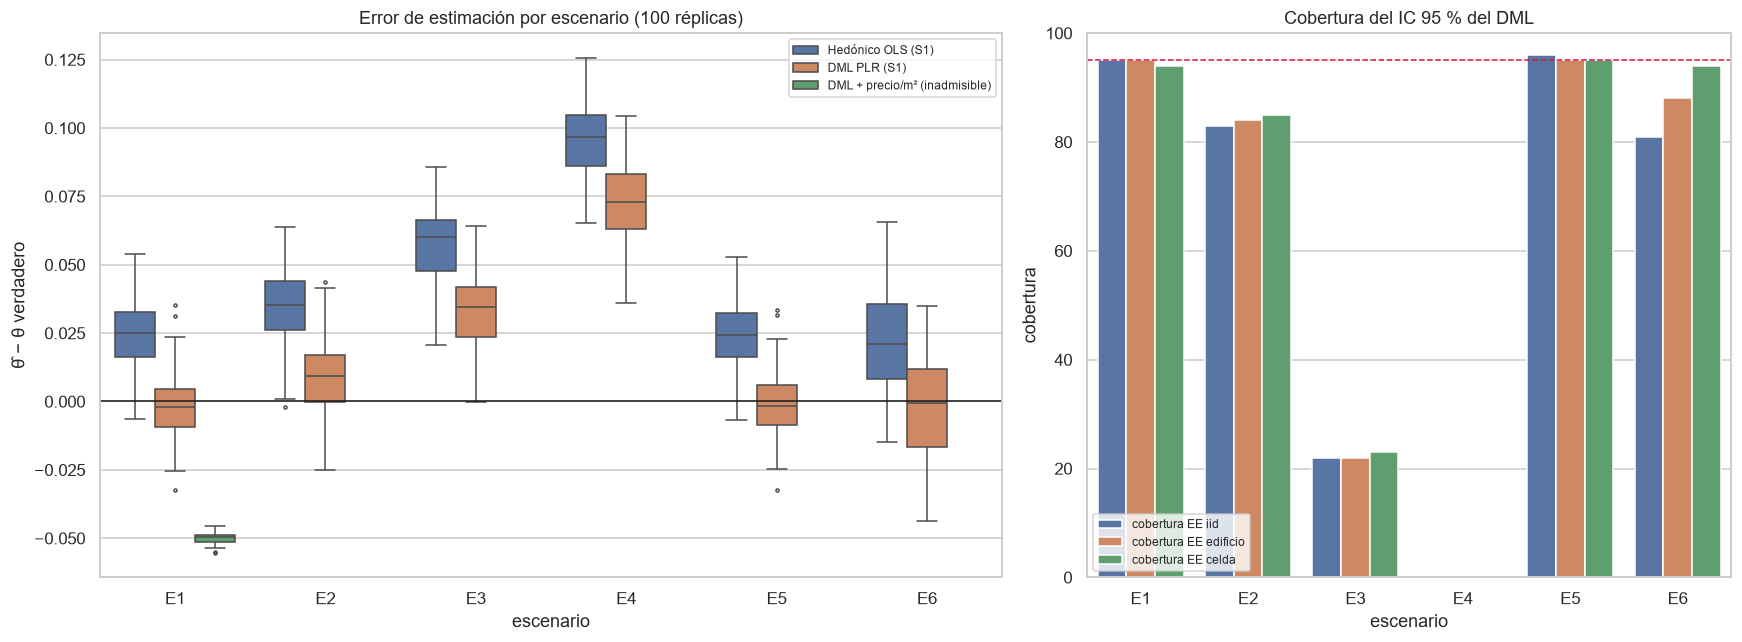

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1]})
sub = est[est.estimador.isin(["Hedónico OLS (S1)", "DML PLR (S1)", "DML + precio/m² (inadmisible)"])].copy()
sub["error"] = sub.theta - sub.verdad
sub["esc"] = sub.escenario.str.split(" ").str[0]
sns.boxplot(data=sub, x="esc", y="error", hue="estimador", ax=ax[0], fliersize=2)
ax[0].axhline(0, color="k", lw=1); ax[0].set_xlabel("escenario"); ax[0].set_ylabel("θ̂ − θ verdadero")
ax[0].set_title("Error de estimación por escenario (100 réplicas)"); ax[0].legend(fontsize=8)
c = r6[r6.estimador == "DML PLR (S1)"].copy(); c["esc"] = c.escenario.str.split(" ").str[0]
cc = c.melt(id_vars="esc", value_vars=["cobertura EE iid", "cobertura EE edificio", "cobertura EE celda"],
            var_name="inferencia", value_name="cobertura")
sns.barplot(data=cc, x="esc", y="cobertura", hue="inferencia", ax=ax[1])
ax[1].axhline(95, color="crimson", ls="--", lw=1); ax[1].set_ylim(0, 100); ax[1].set_xlabel("escenario")
ax[1].set_title("Cobertura del IC 95 % del DML"); ax[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(FIG / "F6_semisintetico.png", bbox_inches="tight"); plt.show()

## Conclusiones de la validación

* **E1 – sin confusión omitida:** el DML es insesgado (sesgo ≈ −0.001) y su IC cubre el 95 %. El hedónico OLS sobreestima en 0.025 y cubre solo el 50 %, aun sin confusores omitidos, porque no absorbe la confusión no lineal. Esto replica el patrón de los datos reales (8.4 % frente a 5.3 %). El control inadmisible precio/m² lleva el efecto a 0.
* **E2–E4 – confusor omitido U:** el DML se sesga en proporción a la fuerza de U (0.009 / 0.033 / 0.073) y la cobertura cae (84 / 22 / 0 %). La cota de sensibilidad evaluada con la fuerza real de U reproduce el sesgo y recupera la cobertura (96 / 96 / 92 %).
* **E5 – heterogeneidad:** los GATE recuperan cada θ por clase (cobertura 91–96 %), pero la prueba de Wald detecta las diferencias solo el 24 % de las veces: con N ≈ 3 000 la potencia es baja.
* **E6 – dependencia espacial:** el DML sigue insesgado. La cobertura iid cae al 81 %; agrupando por edificio llega al 88 % y por bloque de 1 km al 94 %.

La simulación no prueba que el efecto real sea causal: muestra cuándo el procedimiento funciona y cuándo falla.